# 🛒 Projet 04 — Analyse des performances commerciales
## Dataset : Superstore | Outil : Python (pandas, seaborn, scipy)
### Objectif : identifier les facteurs qui influencent les ventes et la rentabilité

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Style global
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("✅ Librairies chargées !")

✅ Librairies chargées !


## 1. Chargement & exploration initiale

In [3]:
df = pd.read_csv('../dataset/superstore.csv', encoding='latin1')

print(f"✅ Dataset chargé : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"\n📋 Colonnes :")
print(df.columns.tolist())
df.head(3)

✅ Dataset chargé : 9994 lignes × 21 colonnes

📋 Colonnes :
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


In [4]:
print("📊 Types de données :")
print(df.dtypes)
print(f"\n❓ Valeurs manquantes :")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\n🔁 Doublons : {df.duplicated().sum()}")

📊 Types de données :
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

❓ Valeurs manquantes :
Series([], dtype: int64)

🔁 Doublons : 0


## 2. Nettoyage des données

In [5]:
# Conversion des dates
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Extraction de l'année et du mois
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month_Name'] = df['Order Date'].dt.strftime('%b')

# Délai de livraison
df['Delivery_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Colonne Marge (%)
df['Margin_Pct'] = (df['Profit'] / df['Sales'] * 100).round(2)

print(f"✅ Nettoyage terminé")
print(f"   Années disponibles : {sorted(df['Year'].unique())}")
print(f"   Délai livraison moyen : {df['Delivery_Days'].mean():.1f} jours")
df[['Order Date', 'Year', 'Month', 'Delivery_Days', 'Margin_Pct']].head(3)

✅ Nettoyage terminé
   Années disponibles : [np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017)]
   Délai livraison moyen : 4.0 jours


,Order Date,Year,Month,Delivery_Days,Margin_Pct
0,2016-11-08,2016,11,3,16.0
1,2016-11-08,2016,11,3,30.0
2,2016-06-12,2016,6,4,47.0


## 3. Statistiques descriptives

In [6]:
print("📈 STATISTIQUES CLÉS\n")

kpis = {
    'CA Total ($)': df['Sales'].sum(),
    'Profit Total ($)': df['Profit'].sum(),
    'Marge globale (%)': df['Profit'].sum() / df['Sales'].sum() * 100,
    'Nb commandes': df['Order ID'].nunique(),
    'Panier moyen ($)': df['Sales'].sum() / df['Order ID'].nunique(),
    'Remise moyenne (%)': df['Discount'].mean() * 100,
    'Délai livraison moyen (j)': df['Delivery_Days'].mean()
}

for k, v in kpis.items():
    print(f"  {k:35s}: {v:,.2f}")

📈 STATISTIQUES CLÉS

  CA Total ($)                       : 2,297,200.86
  Profit Total ($)                   : 286,397.02
  Marge globale (%)                  : 12.47
  Nb commandes                       : 5,009.00
  Panier moyen ($)                   : 458.61
  Remise moyenne (%)                 : 15.62
  Délai livraison moyen (j)          : 3.96


## 4. Analyse par dimension

In [7]:
print("📦 PERFORMANCE PAR CATÉGORIE\n")
cat = df.groupby('Category').agg(
    CA=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Nb_commandes=('Order ID', 'nunique'),
    Marge_pct=('Margin_Pct', 'mean')
).round(2)
cat['CA_pct'] = (cat['CA'] / cat['CA'].sum() * 100).round(1)
print(cat.sort_values('CA', ascending=False))

📦 PERFORMANCE PAR CATÉGORIE

                        CA     Profit  Nb_commandes  Marge_pct  CA_pct
Category                                                              
Technology       836154.03  145454.95          1544      15.61    36.4
Furniture        741999.80   18451.27          1764       3.88    32.3
Office Supplies  719047.03  122490.80          3742      13.80    31.3


In [8]:
print("🗺️ PERFORMANCE PAR RÉGION\n")
region = df.groupby('Region').agg(
    CA=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Marge_pct=('Margin_Pct', 'mean')
).round(2)
region['CA_pct'] = (region['CA'] / region['CA'].sum() * 100).round(1)
print(region.sort_values('Profit', ascending=False))

🗺️ PERFORMANCE PAR RÉGION

                CA     Profit  Marge_pct  CA_pct
Region                                          
West     725457.82  108418.45      21.95    31.6
East     678781.24   91522.78      16.72    29.5
South    391721.90   46749.43      16.35    17.1
Central  501239.89   39706.36     -10.41    21.8


In [9]:
print("👥 PERFORMANCE PAR SEGMENT\n")
segment = df.groupby('Segment').agg(
    CA=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Marge_pct=('Margin_Pct', 'mean')
).round(2)
print(segment.sort_values('CA', ascending=False))

👥 PERFORMANCE PAR SEGMENT

                     CA     Profit  Marge_pct
Segment                                      
Consumer     1161401.34  134119.21      11.20
Corporate     706146.37   91979.13      12.12
Home Office   429653.15   60298.68      14.29


## 5. Visualisations

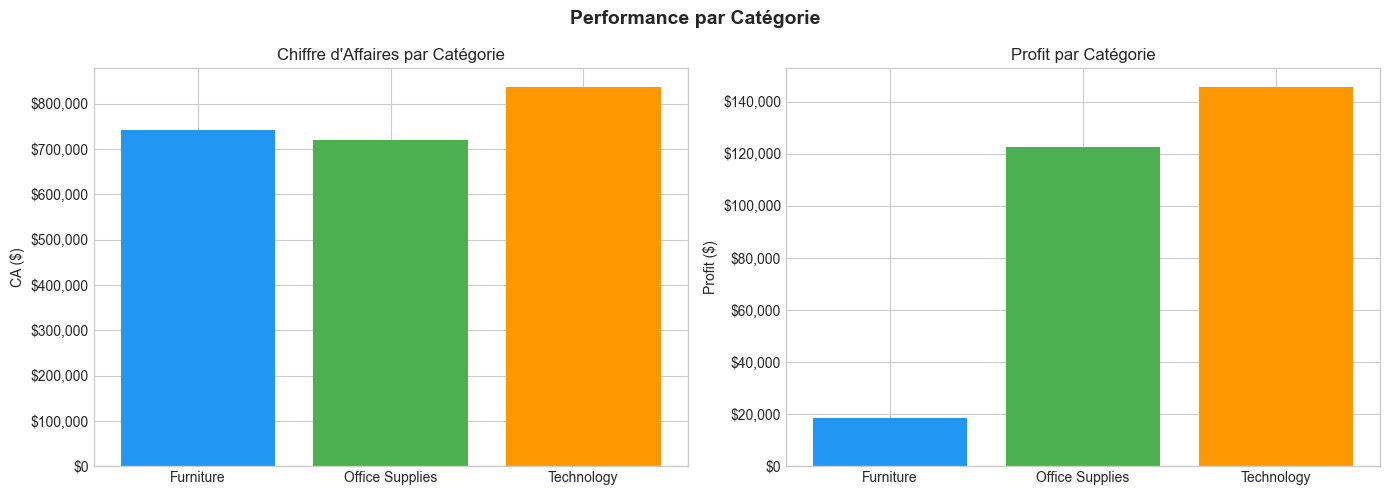

✅ Image sauvegardée


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Performance par Catégorie', fontsize=14, fontweight='bold')

categories = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()

axes[0].bar(categories['Category'], categories['Sales'], color=['#2196F3','#4CAF50','#FF9800'])
axes[0].set_title('Chiffre d\'Affaires par Catégorie')
axes[0].set_ylabel('CA ($)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))

axes[1].bar(categories['Category'], categories['Profit'], color=['#2196F3','#4CAF50','#FF9800'])
axes[1].set_title('Profit par Catégorie')
axes[1].set_ylabel('Profit ($)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.savefig('../images/01_performance_categorie.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

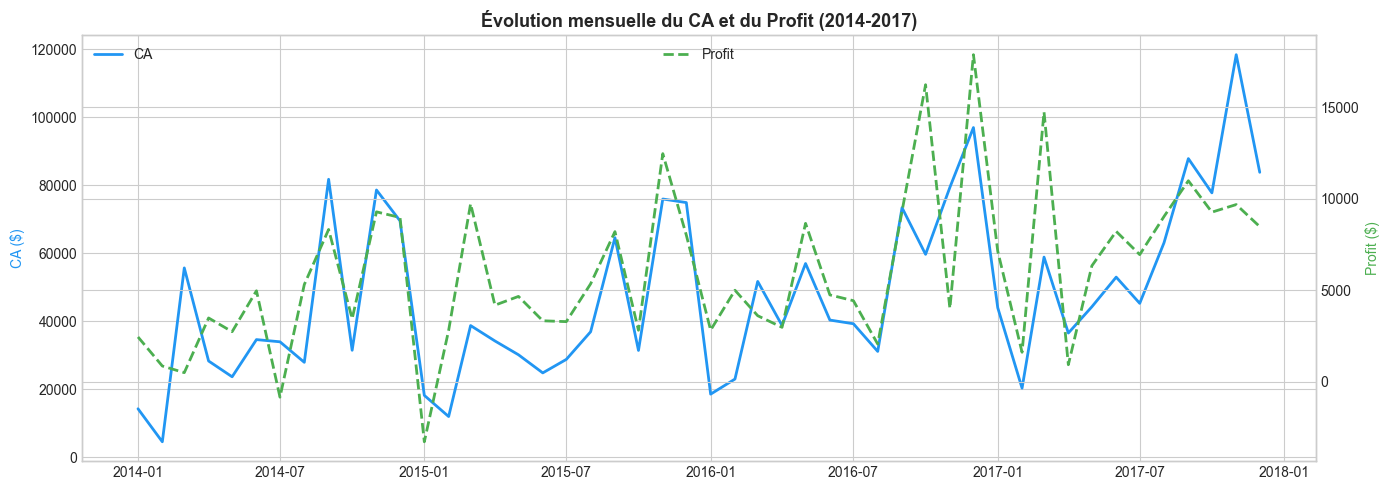

✅ Image sauvegardée


In [11]:
fig, ax = plt.subplots(figsize=(14, 5))

monthly = df.groupby(['Year', 'Month'])[['Sales', 'Profit']].sum().reset_index()
monthly['Date'] = pd.to_datetime(monthly[['Year', 'Month']].assign(day=1))
monthly = monthly.sort_values('Date')

ax.plot(monthly['Date'], monthly['Sales'], label='CA', color='#2196F3', linewidth=2)
ax2 = ax.twinx()
ax2.plot(monthly['Date'], monthly['Profit'], label='Profit', color='#4CAF50', linewidth=2, linestyle='--')

ax.set_title('Évolution mensuelle du CA et du Profit (2014-2017)', fontsize=13, fontweight='bold')
ax.set_ylabel('CA ($)', color='#2196F3')
ax2.set_ylabel('Profit ($)', color='#4CAF50')
ax.legend(loc='upper left')
ax2.legend(loc='upper center')

plt.tight_layout()
plt.savefig('../images/02_evolution_temporelle.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

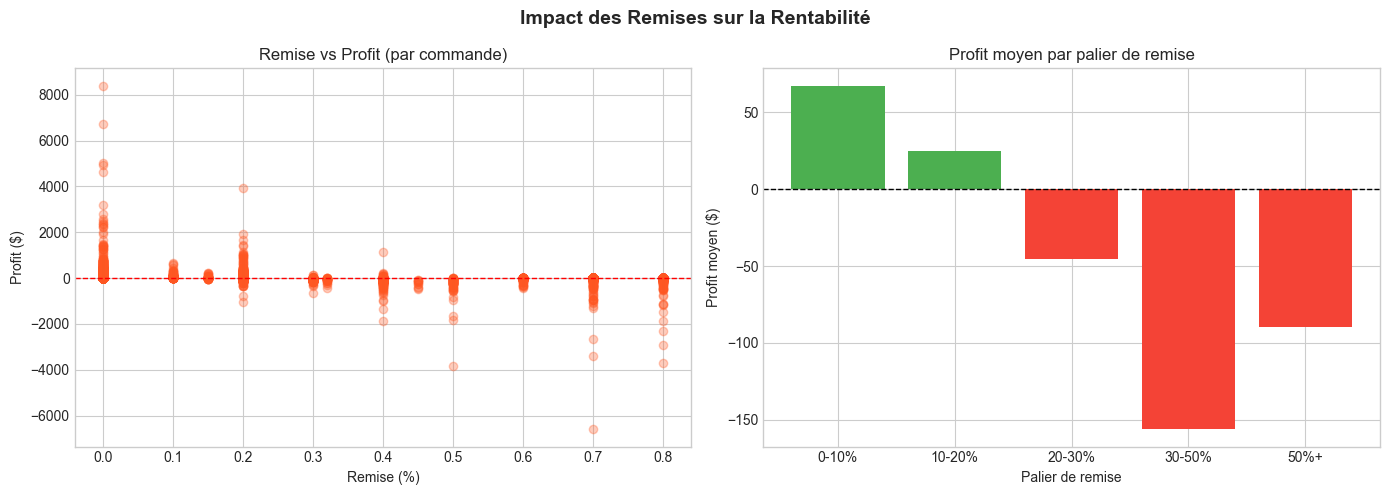

✅ Image sauvegardée


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Impact des Remises sur la Rentabilité', fontsize=14, fontweight='bold')

# Scatter : Remise vs Profit
axes[0].scatter(df['Discount'], df['Profit'], alpha=0.3, color='#FF5722')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=1)
axes[0].set_xlabel('Remise (%)')
axes[0].set_ylabel('Profit ($)')
axes[0].set_title('Remise vs Profit (par commande)')

# Profit moyen par palier de remise
df['Discount_bin'] = pd.cut(df['Discount'], bins=[0, 0.1, 0.2, 0.3, 0.5, 0.9],
                             labels=['0-10%', '10-20%', '20-30%', '30-50%', '50%+'],
                             include_lowest=True)
profit_by_disc = df.groupby('Discount_bin', observed=True)['Profit'].mean()
colors = ['#4CAF50' if v > 0 else '#F44336' for v in profit_by_disc.values]
axes[1].bar(profit_by_disc.index, profit_by_disc.values, color=colors)
axes[1].axhline(y=0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Palier de remise')
axes[1].set_ylabel('Profit moyen ($)')
axes[1].set_title('Profit moyen par palier de remise')

plt.tight_layout()
plt.savefig('../images/03_impact_remises.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

C:\Users\barde\AppData\Local\Temp\ipykernel_14524\29287795.py:19: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\barde\AppData\Local\Temp\ipykernel_14524\29287795.py:19: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\barde\AppData\Local\Temp\ipykernel_14524\29287795.py:19: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\barde\AppData\Local\Temp\ipykernel_14524\29287795.py:20: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.savefig('../images/04_top_flop_souscategories.png', dpi=150, bbox_inches='tight')
C:\Users\barde\AppData\Local\Temp\ipykernel_14524\29287795.py:20: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.savefig('../images/04_top_flop_souscategories.png', dpi=150, bbox_inches='tight')
C:\Users\barde\AppData\Local\Temp\ipykernel_14524\2928

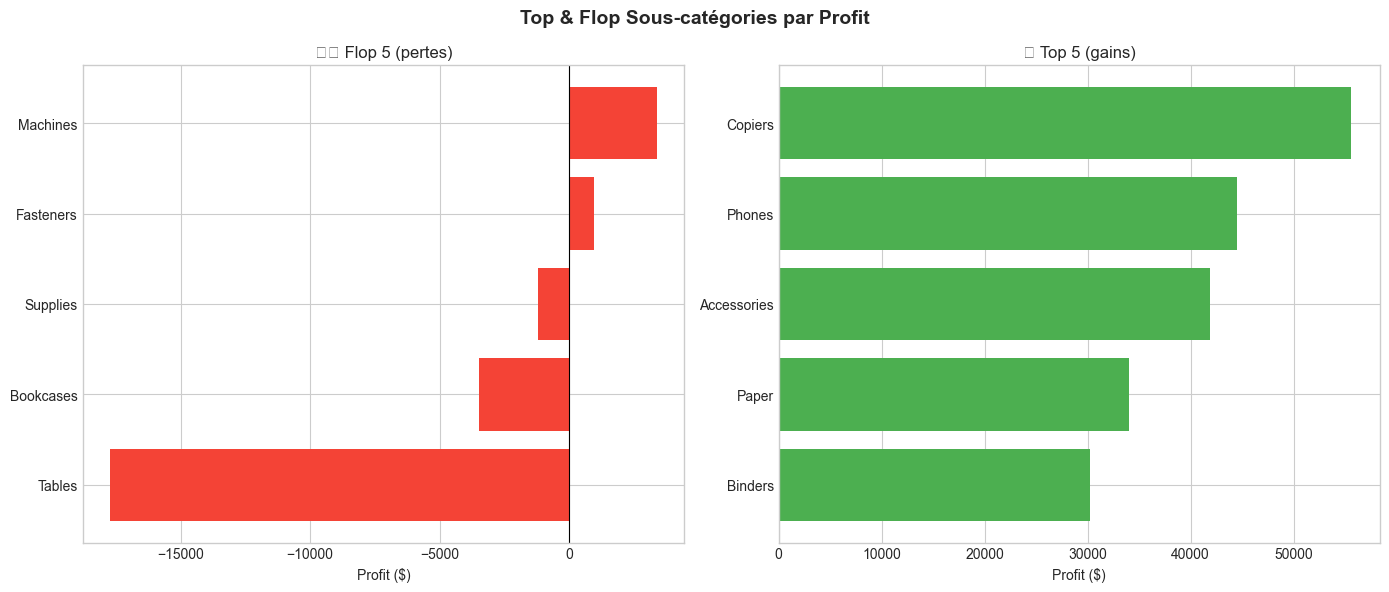

✅ Image sauvegardée


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Top & Flop Sous-catégories par Profit', fontsize=14, fontweight='bold')

subcat = df.groupby('Sub-Category')['Profit'].sum().sort_values()

# Flop 5
flop = subcat.head(5)
axes[0].barh(flop.index, flop.values, color='#F44336')
axes[0].set_title('⚠️ Flop 5 (pertes)')
axes[0].set_xlabel('Profit ($)')
axes[0].axvline(x=0, color='black', linewidth=0.8)

# Top 5
top = subcat.tail(5)
axes[1].barh(top.index, top.values, color='#4CAF50')
axes[1].set_title('🌟 Top 5 (gains)')
axes[1].set_xlabel('Profit ($)')

plt.tight_layout()
plt.savefig('../images/04_top_flop_souscategories.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

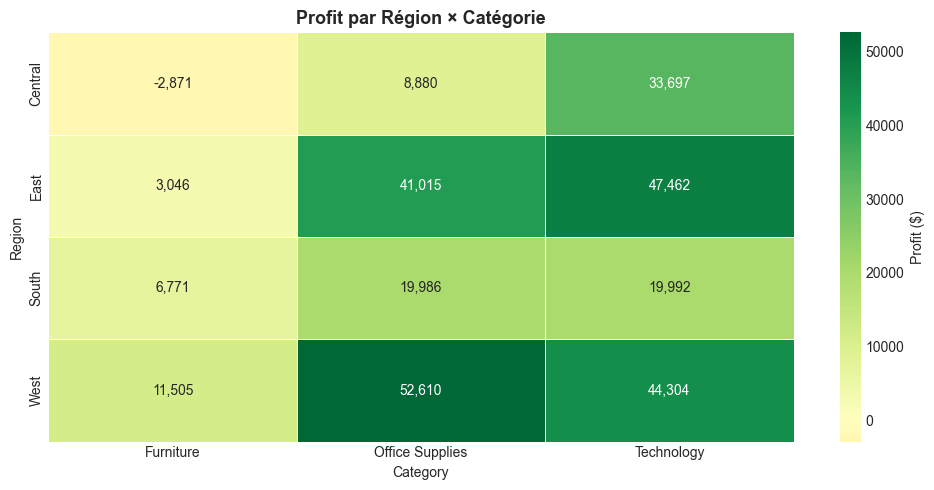

✅ Image sauvegardée


In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

pivot = df.pivot_table(values='Profit', index='Region', columns='Category', aggfunc='sum')
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='RdYlGn', center=0, ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Profit ($)'})
ax.set_title('Profit par Région × Catégorie', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../images/05_heatmap_region_categorie.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

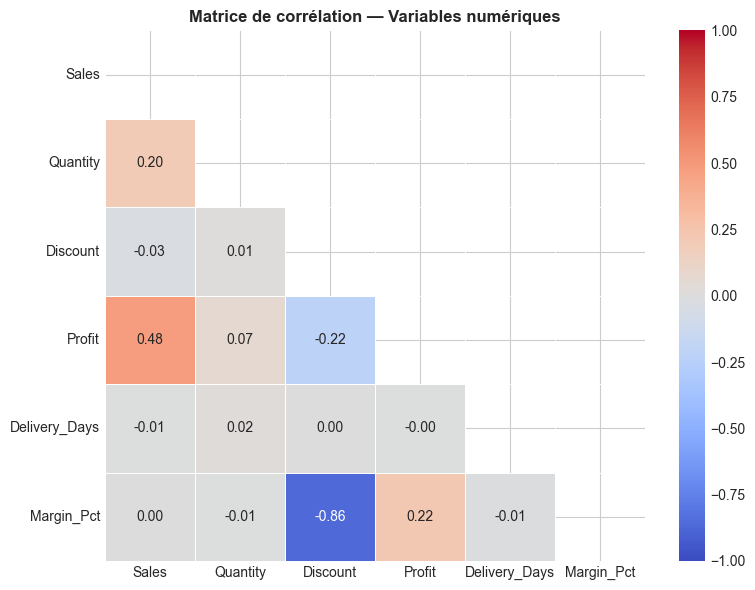

✅ Image sauvegardée


In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

cols_num = ['Sales', 'Quantity', 'Discount', 'Profit', 'Delivery_Days', 'Margin_Pct']
corr = df[cols_num].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title('Matrice de corrélation — Variables numériques', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../images/06_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Image sauvegardée")

## 6. Analyse de corrélation (test statistique)

In [16]:
print("📊 CORRÉLATIONS AVEC LE PROFIT (Pearson)\n")

variables = ['Sales', 'Quantity', 'Discount', 'Delivery_Days']
for var in variables:
    r, p = stats.pearsonr(df[var], df['Profit'])
    significance = "✅ significatif" if p < 0.05 else "❌ non significatif"
    print(f"  Profit ~ {var:20s} : r = {r:+.3f}  (p={p:.4f}) {significance}")

print("\n💡 Interprétation :")
print("  r proche de +1 → corrélation positive forte")
print("  r proche de -1 → corrélation négative forte")
print("  r proche de  0 → pas de corrélation linéaire")

📊 CORRÉLATIONS AVEC LE PROFIT (Pearson)

  Profit ~ Sales                : r = +0.479  (p=0.0000) ✅ significatif
  Profit ~ Quantity             : r = +0.066  (p=0.0000) ✅ significatif
  Profit ~ Discount             : r = -0.219  (p=0.0000) ✅ significatif
  Profit ~ Delivery_Days        : r = -0.005  (p=0.6421) ❌ non significatif

💡 Interprétation :
  r proche de +1 → corrélation positive forte
  r proche de -1 → corrélation négative forte
  r proche de  0 → pas de corrélation linéaire


## 7. Sous-catégories déficitaires — analyse détaillée

In [17]:
print("⚠️ SOUS-CATÉGORIES DÉFICITAIRES\n")

subcat_detail = df.groupby('Sub-Category').agg(
    CA=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Nb_lignes=('Sales', 'count'),
    Remise_moy=('Discount', 'mean'),
    Marge_moy=('Margin_Pct', 'mean')
).round(2)

deficitaires = subcat_detail[subcat_detail['Profit'] < 0].sort_values('Profit')
print(deficitaires)

print(f"\n💸 Pertes totales sur ces sous-catégories : ${deficitaires['Profit'].sum():,.0f}")

⚠️ SOUS-CATÉGORIES DÉFICITAIRES

                     CA    Profit  Nb_lignes  Remise_moy  Marge_moy
Sub-Category                                                       
Tables        206965.53 -17725.48        319        0.26     -14.77
Bookcases     114880.00  -3472.56        228        0.21     -12.66
Supplies       46673.54  -1189.10        190        0.08      11.20

💸 Pertes totales sur ces sous-catégories : $-22,387


## 8. Insights & Recommandations

In [18]:
print("=" * 60)
print("💡 INSIGHTS CLÉS — PROJET 04")
print("=" * 60)

print("""
📈 PERFORMANCE GLOBALE
  CA Total     : $2,297,201
  Profit Total : $286,397
  Marge globale: 12.5%

🏆 CE QUI PERFORME
  → Technology = catégorie la plus rentable
  → West = région avec la meilleure marge
  → Copiers, Phones, Accessories = sous-catégories vedettes

⚠️ CE QUI FAIT PERDRE DE L'ARGENT
  → Tables       : pertes importantes (-8.6% de marge)
  → Bookcases    : déficitaire (-3%)
  → Supplies     : déficitaire (-2.5%)
  → Remises > 20% = systématiquement non rentables

🔗 CORRÉLATIONS IMPORTANTES
  → Discount ~ Profit : corrélation NÉGATIVE forte
    (plus on fait de remise, moins on est rentable)
  → Sales ~ Profit    : corrélation positive modérée
  → Quantity a peu d'impact sur le profit

🎯 RECOMMANDATIONS
  1. Plafonner les remises à 20% maximum
  2. Revoir la politique tarifaire sur Tables et Bookcases
  3. Booster Technology en région Central (sous-exploité)
  4. Surveiller les commandes avec Discount > 30%
""")

💡 INSIGHTS CLÉS — PROJET 04

📈 PERFORMANCE GLOBALE
  CA Total     : $2,297,201
  Profit Total : $286,397
  Marge globale: 12.5%

🏆 CE QUI PERFORME
  → Technology = catégorie la plus rentable
  → West = région avec la meilleure marge
  → Copiers, Phones, Accessories = sous-catégories vedettes

⚠️ CE QUI FAIT PERDRE DE L'ARGENT
  → Tables       : pertes importantes (-8.6% de marge)
  → Bookcases    : déficitaire (-3%)
  → Supplies     : déficitaire (-2.5%)
  → Remises > 20% = systématiquement non rentables

🔗 CORRÉLATIONS IMPORTANTES
  → Discount ~ Profit : corrélation NÉGATIVE forte
    (plus on fait de remise, moins on est rentable)
  → Sales ~ Profit    : corrélation positive modérée
  → Quantity a peu d'impact sur le profit

🎯 RECOMMANDATIONS
  1. Plafonner les remises à 20% maximum
  2. Revoir la politique tarifaire sur Tables et Bookcases
  3. Booster Technology en région Central (sous-exploité)
  4. Surveiller les commandes avec Discount > 30%

